In [2]:
# Setup for rest of the notebook
# Easier way to work with files and directories
from pathlib import Path
# Creates plots and figures
import matplotlib.pyplot as plt
# Provides arrays and numerical operations
import numpy as np

# Core Qiskit imports
# QuantumCircuit is used to construct a quantum circuit
# Transpile converts the abstract circuit into instructions suitable for a selected backend
from qiskit import QuantumCircuit, transpile
# Statevector for representing a pure quantum state as a complex vector
from qiskit.quantum_info import Statevector
# Qiskit visualisation functions
# plot_bloch_multivector displays qubit states using Bloch spheres
# plot_histogram displays measurement counts
from qiskit.visualization import plot_bloch_multivector, plot_histogram
# AerSimulator runs Qiskit circuits on a classical computer
from qiskit_aer import AerSimulator
# NoiseModel is a container describing which errors should be applied to which circuit instructions
# depolarizing_error constructs a depolarising error channel
# pauli_error constructs a custom probabilistic combination of Pauli operations
from qiskit_aer.noise import NoiseModel, depolarizing_error, pauli_error

# Reproducibility constants
# A shot is one execution and measurement of a circuit, more shots generally reduce sampling uncertainty. I chose 4096 because powers of 2 are easier to work with (like calculating standard error)
# The seed makes pseudo-random behaviour reproducible, and 42 is a commonly used value that can I chose for consistency
SHOTS = 4096
SEED = 42

# Project directories for windows. Script exist for MacBook conversion.
PROJECT_DIR = Path(r"C:\Users\Karthi\Qauntum")
# Output subdirectories
FIGURE_DIR = PROJECT_DIR / "figures"
RESULTS_DIR = PROJECT_DIR / "results"

# Creating the directories
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Checks they exist
print(f"Project directory: {PROJECT_DIR}")
print(f"Figure directory: {FIGURE_DIR}")
print(f"Results directory: {RESULTS_DIR}")
print("Environment ready")

Project directory: C:\Users\Karthi\Qauntum
Figure directory: C:\Users\Karthi\Qauntum\figures
Results directory: C:\Users\Karthi\Qauntum\results
Environment ready


In [3]:
# circuit - Qiskit QuantumCircuit to execute
# shots=SHOTS - one independent execution of the circuit followed by measurement
# noise_model=None - optional noise model that we will not be using
# seed=SEED - pseudo-random behaviour, making results reproducible
def run_counts(circuit, shots=SHOTS, noise_model=None, seed=SEED):

    # Creates a Qiskit Aer simulator backend
    simulator = AerSimulator(
        noise_model=noise_model,
        seed_simulator=seed,
    )
    # transpile() step converts it into a form compatible with the selected simulator
    compiled_circuit = transpile(
        circuit,
        simulator,
        seed_transpiler=seed,
    )
    # Runs the experiment
    result = simulator.run(
        compiled_circuit,
        shots=shots,
    ).result()
    # Returns the measurement counts
    return result.get_counts()

     ┌─┐
  q: ┤M├
     └╥┘
c: 1/═╩═
      0 
Measurement counts: {'0': 4096}


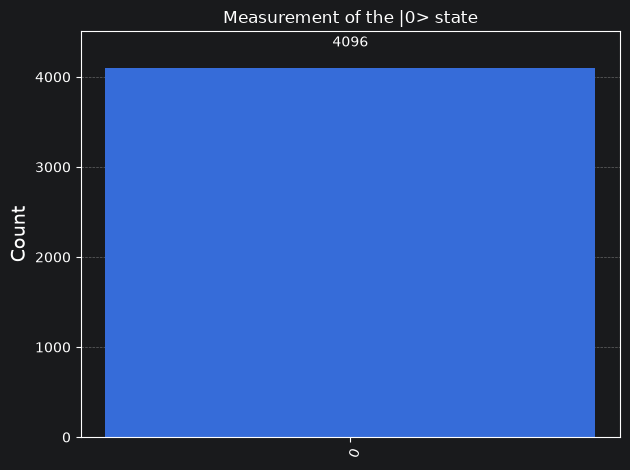

In [11]:
# Simplest possible measured quantum circuit for sanity check
# Creates the circuit that contains one quantum bit and one classical bit for storing the measurement result
zero_circuit = QuantumCircuit(1, 1)
# Measures qubit 0 and stores the result in classical bit 0
zero_circuit.measure(0, 0)

# Simulate the circuit by passing run_counts
# No noise model is supplied, this is an ideal simulation with expected result {"0": 4096}, which is stored in zero_counts
zero_counts = run_counts(zero_circuit)

# Print the circuit
# q is the quantum register
# c is the classical register
# M is the measurement operation
# measurement result from qubit 0 is sent to classical bit 0
print(zero_circuit)
# Print the measurement counts
print("Measurement counts:", zero_counts)

# Gives AssertionError if not true
assert zero_counts == {
    "0": SHOTS,
}

# Plot the measurement histogram
plot_histogram(
    zero_counts,
    title="Measurement of the |0> state",
)

In [15]:
# Checks that the notebook can write a file into the project’s results directory, then confirms that the file exists
test_file = RESULTS_DIR / "setup_test.txt"
test_file.write_text(
    "Qiskit setup successful.\n",
    encoding="utf-8",
)

print(f"Created: {test_file}")
print(f"File exists: {test_file.exists()}")

Created: C:\Users\Karthi\Qauntum\results\setup_test.txt
File exists: True


## Computational-basis states

The X gate transforms the initial state |0> into |1>. Measuring the resulting state should therefore always return 1 in an ideal simulation.

     ┌───┐┌─┐
  q: ┤ X ├┤M├
     └───┘└╥┘
c: 1/══════╩═
           0 
Measurement counts: {'1': 4096}


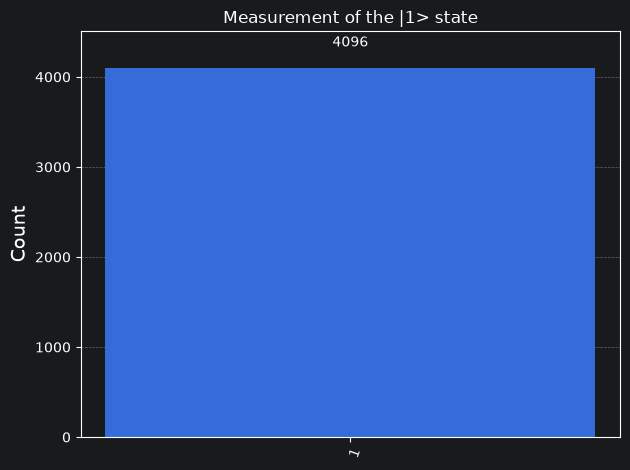

In [17]:
# Prepares and measures a qubit in the ∣1⟩ state, the counterpart to the earlier ∣0⟩ example
# Creates the circuit that contains one quantum bit and one classical bit for storing the measurement result
one_circuit = QuantumCircuit(1, 1)

# Apply the Pauli-X gate
# Transform |0> into |1>
one_circuit.x(0)

# Measure qubit 0 into classical bit 0.
one_circuit.measure(0, 0)

# Run the simulation
one_counts = run_counts(one_circuit)

# Print the circuit
# q is the quantum register
# c is the classical register
# M is the measurement operation
# measurement result from qubit 0 is sent to classical bit 0
print(one_circuit.draw())
# Print the measurement counts
print("Measurement counts:", one_counts)

# Gives AssertionError if not true
assert one_counts == {
    "1": SHOTS,
}

# Plot the measurement histogram
plot_histogram(
    one_counts,
    title="Measurement of the |1> state",
)

## Quantum superposition

Applying a Hadamard gate to |0> produces the state

|+> = (|0> + |1>) / sqrt(2).

The ideal probabilities of measuring 0 and 1 are therefore both 0.5. Finite-shot simulation will generally produce approximately, rather than exactly, equal counts.

     ┌───┐┌─┐
  q: ┤ H ├┤M├
     └───┘└╥┘
c: 1/══════╩═
           0 
Measurement counts: {'1': 2074, '0': 2022}


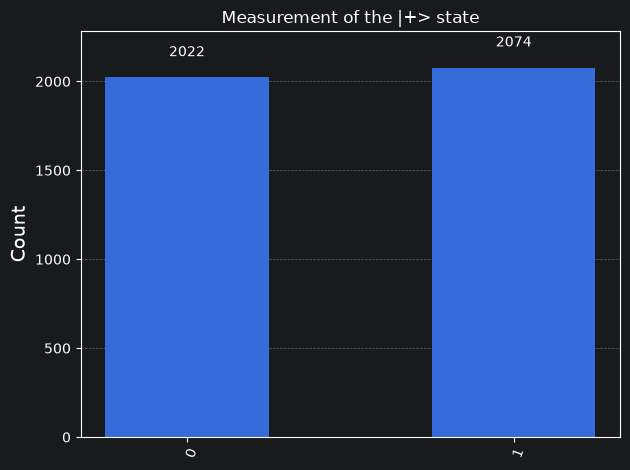

In [19]:
# Creates the circuit that contains one quantum bit and one classical bit for storing the measurement result
plus_circuit = QuantumCircuit(1, 1)

# Applies a Hadamard gate to qubit 0, putting it into the |+> state
plus_circuit.h(0)
# Measure qubit 0 into classical bit 0.
plus_circuit.measure(0, 0)

# Executes the circuit 4096 times
plus_counts = run_counts(plus_circuit)

# Prints the quantum circuit
print(plus_circuit.draw())
# Print the measurement counts, should be roughly equal.
print("Measurement counts:", plus_counts)

# Plot the measurement histogram
plot_histogram(
    plus_counts,
    title="Measurement of the |+> state",
)

In [20]:
# Python function converts raw measurement counts from a quantum circuit into a sorted dictionary of probabilities ranging from 0.0 to 1.0
def counts_to_probabilities(counts):
    # Convert a Qiskit counts dictionary into probabilities
    total_shots = sum(counts.values())

    return {
        outcome: count / total_shots
        for outcome, count in sorted(counts.items())
    }

In [22]:
# Calls the helper function to turn raw shot counts into a dictionary of probabilities
plus_probabilities = counts_to_probabilities(plus_counts)

# Extracts the probability for measuring 0 and 1
probability_zero = plus_probabilities.get("0", 0.0)
probability_one = plus_probabilities.get("1", 0.0)

# Prints each probability formatted to 4 decimal places
print(f"Observed P(0): {probability_zero:.4f}")
print(f"Observed P(1): {probability_one:.4f}")
# Sum to 1 to confirm all measurement outcomes are accounted for
print(f"Probability sum: {probability_zero + probability_one:.4f}")

Observed P(0): 0.4937
Observed P(1): 0.5063
Probability sum: 1.0000


In [23]:
# uses isclose() to verify that probabilities sum up to 1, as it has a small tolerance to account for floating point rounding
assert np.isclose(
    probability_zero + probability_one,
    1.0,
)

# Checks probabilities are within 5% of ideal theoretical value
assert abs(probability_zero - 0.5) < 0.05
assert abs(probability_one - 0.5) < 0.05

print("The measured probabilities are consistent with the |+> state.")

The measured probabilities are consistent with the |+> state.


In [24]:
# Creates the circuit that contains one quantum bit and zero classical bit for storing the measurement result
plus_state_circuit = QuantumCircuit(1)
# Applies hadamard gate to put quantum bit into |+> state
plus_state_circuit.h(0)

# Uses Statevector class to analytically compute the exact quantum state produced by the circuit's gates
plus_state = Statevector.from_instruction(
    plus_state_circuit
)

# Outputs the raw complex probability amplitudes as a NumPy array
print("Statevector amplitudes:")
print(plus_state.data)

# Squares the magnitude of each amplitude and returns the exact theoretical probabilities
print("\nExact basis probabilities:")
print(plus_state.probabilities_dict())


Statevector amplitudes:
[0.70710678+0.j 0.70710678+0.j]

Exact basis probabilities:
{np.str_('0'): np.float64(0.4999999999999999), np.str_('1'): np.float64(0.4999999999999999)}


In [26]:
# Extracts the raw NumPy array of complex probability amplitudes from the Statevector
amplitudes = plus_state.data
# Implements the Born rule to get probability from squared modulus
probabilities = np.abs(amplitudes) ** 2
# Adds up all individual basis probabilities to check the total probability across all possible states
normalization = np.sum(probabilities)

# Prints probabilities
print("Probabilities calculated from amplitudes:")
print(probabilities)

# Prints the total sum to 12 decimal places
print(f"\nState normalization: {normalization:.12f}")

# Runs an automated check confirming that the total probability equals 1.0
assert np.isclose(normalization, 1.0)

# Confirmation that the check passed
print("The statevector is correctly normalized.")

Probabilities calculated from amplitudes:
[0.5 0.5]

State normalization: 1.000000000000
The statevector is correctly normalized.


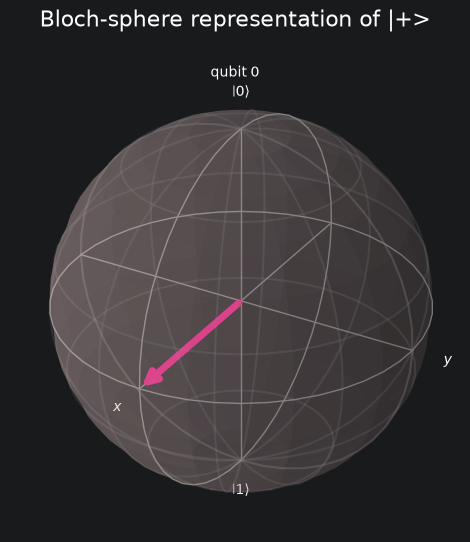

In [27]:
# Plots the Bloch-sphere representation of |+>
plot_bloch_multivector(
    plus_state,
    title="Bloch-sphere representation of |+>",
)

In [28]:
# Uses Qiskit's plot_histogram() to turn plus_counts dictionary into a Matplotlib Figure, howing the frequencies (or probabilities) of measuring '0' and '1'
figure = plot_histogram(
    plus_counts,
    title="Measurement of the |+> state",
)

# handles path of output file
output_path = FIGURE_DIR / "plus_state_measurements.png"

figure.savefig(
    output_path,
    dpi=200,
    bbox_inches="tight",
)

print(f"Saved figure to: {output_path}")

Saved figure to: C:\Users\Karthi\Qauntum\figures\plus_state_measurements.png


## Finite-shot sampling

Quantum measurement is probabilistic. For the |+> state, the theoretical probabilities are P(0) = P(1) = 0.5, but a finite number of circuit executions will not normally produce an exact 50:50 split.

This experiment measures the |+> state using different numbers of shots and examines how the estimated probability approaches the theoretical value.

In [29]:
# Defines a list of sample sizes increasing by powers of 4, to test how sample size affects measurement accuracy
shot_values = [16, 64, 256, 1024, 4096, 16384]

# Initialises an empty list to store the structured results from each run
finite_shot_results = []

for shots in shot_values:
    # Executes plus_circuit for the current shots value
    counts = run_counts(
        plus_circuit,
        shots=shots,
        seed=SEED,
    )
    # Safely extracts the raw hit counts for '0' and '1'
    # Defaults to 0 if an outcome didn't occur
    zero_count = counts.get("0", 0)
    one_count = counts.get("1", 0)

    # Calculates the observed probabilities for each outcome
    probability_zero = zero_count / shots
    probability_one = one_count / shots

    #Saves a dictionary containing the shot count, raw counts, and probabilities into results list
    finite_shot_results.append(
        {
            "shots": shots,
            "zero_count": zero_count,
            "one_count": one_count,
            "probability_zero": probability_zero,
            "probability_one": probability_one,
        }
    )
    # See P(0) and P(1) stabilize near 0.5000 as shots grows
    print(
        f"Shots: {shots:5d} | "
        f"0 count: {zero_count:5d} | "
        f"1 count: {one_count:5d} | "
        f"P(0): {probability_zero:.4f} | "
        f"P(1): {probability_one:.4f}"
    )

Shots:    16 | 0 count:     6 | 1 count:    10 | P(0): 0.3750 | P(1): 0.6250
Shots:    64 | 0 count:    34 | 1 count:    30 | P(0): 0.5312 | P(1): 0.4688
Shots:   256 | 0 count:   141 | 1 count:   115 | P(0): 0.5508 | P(1): 0.4492
Shots:  1024 | 0 count:   526 | 1 count:   498 | P(0): 0.5137 | P(1): 0.4863
Shots:  4096 | 0 count:  2022 | 1 count:  2074 | P(0): 0.4937 | P(1): 0.5063
Shots: 16384 | 0 count:  8161 | 1 count:  8223 | P(0): 0.4981 | P(1): 0.5019


In [31]:
#  converts finite_shot_results from being a list of dictionaries into a structured pandas DataFrame and displays it as a table
import pandas as pd

finite_shot_df = pd.DataFrame(finite_shot_results)

finite_shot_df

,shots,zero_count,one_count,probability_zero,probability_one
0,16,6,10,0.375000,0.625000
1,64,34,30,0.531250,0.468750
2,256,141,115,0.550781,0.449219
3,1024,526,498,0.513672,0.486328
4,4096,2022,2074,0.493652,0.506348
5,16384,8161,8223,0.498108,0.501892


In [32]:
# Calculate the absolute difference between the observed P(0) and the theoretical 0.5 probability,
# storing the result in a new "absolute_error" column to measure shot noise at each sample size
finite_shot_df["absolute_error"] = (
    finite_shot_df["probability_zero"] - 0.5
).abs()

# Display the updated DataFrame with the new error column included
finite_shot_df

,shots,zero_count,one_count,probability_zero,probability_one,absolute_error
0,16,6,10,0.375000,0.625000,0.125000
1,64,34,30,0.531250,0.468750,0.031250
2,256,141,115,0.550781,0.449219,0.050781
3,1024,526,498,0.513672,0.486328,0.013672
4,4096,2022,2074,0.493652,0.506348,0.006348
5,16384,8161,8223,0.498108,0.501892,0.001892


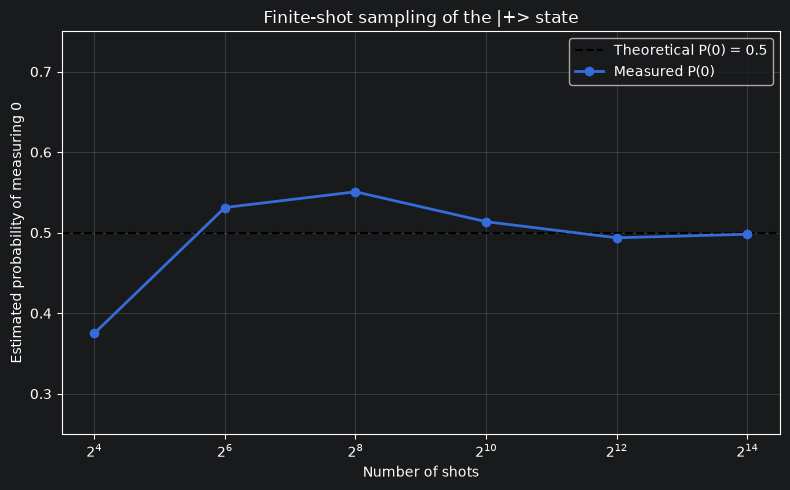

Saved figure to: C:\Users\Karthi\Qauntum\figures\finite_shot_probability.png


In [33]:
# Initialise a Matplotlib figure and single subplot axis
figure, axis = plt.subplots(figsize=(8, 5))

# Draw a horizontal dashed reference line at y = 0.5 representing the ideal |+> state probability
axis.axhline(
    y=0.5,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label="Theoretical P(0) = 0.5",
)

# Plot the experimentally measured P(0) values across increasing shot counts
axis.plot(
    finite_shot_df["shots"],
    finite_shot_df["probability_zero"],
    marker="o",
    linewidth=2,
    label="Measured P(0)",
)

# Format the axes, labels, title, grid, and legend
axis.set_xscale("log", base=2) # Use a base-2 log scale so powers of 4 space evenly
axis.set_xlabel("Number of shots")
axis.set_ylabel("Estimated probability of measuring 0")
axis.set_title("Finite-shot sampling of the |+> state")
axis.set_ylim(0.25, 0.75)  # Centre the y-axis around 0.5
axis.grid(True, alpha=0.3)  # Add a background grid for readability
axis.legend()

# Adjust subplot padding to prevent overlapping labels
figure.tight_layout()

# Construct the output file path and save a PNG copy
probability_figure_path = (
    FIGURE_DIR / "finite_shot_probability.png"
)

figure.savefig(
    probability_figure_path,
    dpi=200,
    bbox_inches="tight",
)

# Render the plot interactively in the notebook
plt.show()
# and confirm the save location
print(f"Saved figure to: {probability_figure_path}")

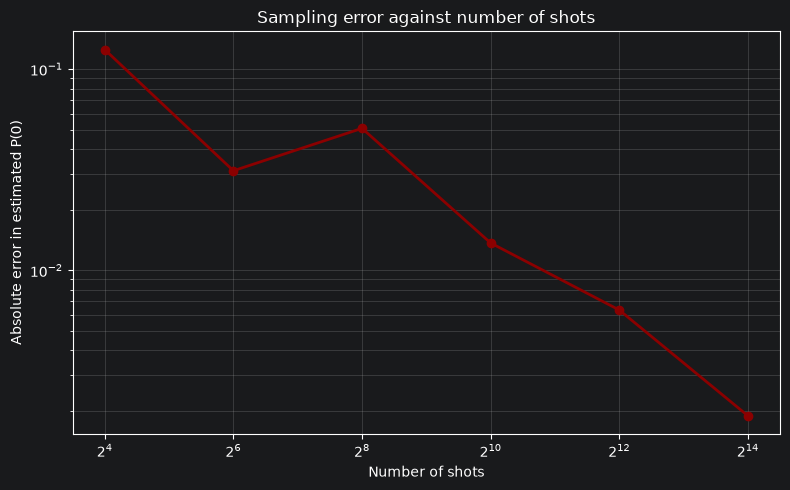

Saved figure to: C:\Users\Karthi\Qauntum\figures\finite_shot_probability.png


In [34]:
# Initialise a Matplotlib figure and single subplot axis
figure, axis = plt.subplots(figsize=(8, 5))

# Plot the absolute sampling error |P(0) - 0.5| against the number of shots
axis.plot(
    finite_shot_df["shots"],
    finite_shot_df["absolute_error"],
    marker="o",
    color="darkred",
    linewidth=2,
)

# Configure log-log scaling and plot formatting to highlight power-law error decay (1 / sqrt(N))
axis.set_xscale("log", base=2) # Base-2 log scale for evenly spaced shot counts
axis.set_yscale("log") # Base-10 log scale to linearise power-law error decay
axis.set_xlabel("Number of shots")
axis.set_ylabel("Absolute error in estimated P(0)")
axis.set_title("Sampling error against number of shots")
axis.grid(True, which="both", alpha=0.3)  # Show both major and minor log gridlines

# Adjust subplot padding to prevent overlapping labels
figure.tight_layout()

# Construct the output file path and save a PNG copy
error_figure_path = (
    FIGURE_DIR / "finite_shot_absolute_error.png"
)

figure.savefig(
    error_figure_path,
    dpi=200,
    bbox_inches="tight",
)

# Render the plot interactively in the notebook
plt.show()
# and confirm the save location
print(f"Saved figure to: {probability_figure_path}")

In [35]:
# Calculate the theoretical standard error for a fair binomial coin flip:
# sigma = sqrt(p * (1 - p) / N) = sqrt(0.5 * 0.5 / N) = 0.5 / sqrt(N)
finite_shot_df["expected_standard_error"] = (
    0.5 / np.sqrt(finite_shot_df["shots"])
)

# Display a focused summary table comparing observed sampling error against theoretical expectations
finite_shot_df[
    [
        "shots",
        "probability_zero",
        "absolute_error",
        "expected_standard_error",
    ]
]

,shots,probability_zero,absolute_error,expected_standard_error
0,16,0.375000,0.125000,0.125000
1,64,0.531250,0.031250,0.062500
2,256,0.550781,0.050781,0.031250
3,1024,0.513672,0.013672,0.015625
4,4096,0.493652,0.006348,0.007812
5,16384,0.498108,0.001892,0.003906


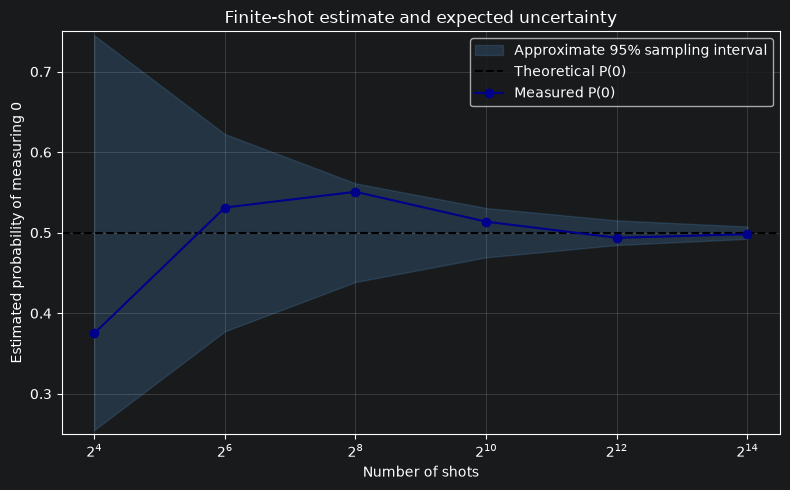

Saved figure to: C:\Users\Karthi\Qauntum\figures\finite_shot_uncertainty.png


In [36]:
# Extract shot counts and theoretical standard errors as NumPy arrays
shots_array = finite_shot_df["shots"].to_numpy()
standard_error = (
    finite_shot_df["expected_standard_error"].to_numpy()
)
# Compute the 95% normal-approximation confidence bounds (mean ± 1.96 * SE) around P(0) = 0.5
lower_bound = 0.5 - (1.96 * standard_error)
upper_bound = 0.5 + (1.96 * standard_error)

# Initialise a Matplotlib figure and single subplot axis
figure, axis = plt.subplots(figsize=(8, 5))

# Shade the region between the lower and upper bounds to show expected 95% sampling variability
axis.fill_between(
    shots_array,
    lower_bound,
    upper_bound,
    alpha=0.25,
    color="steelblue",
    label="Approximate 95% sampling interval",
)
# Draw a horizontal dashed reference line at y = 0.5 for the ideal theoretical probability
axis.axhline(
    y=0.5,
    color="black",
    linestyle="--",
    label="Theoretical P(0)",
)
# Plot the experimentally measured P(0) values across increasing shot counts
axis.plot(
    shots_array,
    finite_shot_df["probability_zero"],
    marker="o",
    color="darkblue",
    label="Measured P(0)",
)
# Configure log-scale x-axis, labels, title, y-limits, grid, and legend
axis.set_xscale("log", base=2) # Base-2 log scale so shot counts space evenly
axis.set_xlabel("Number of shots")
axis.set_ylabel("Estimated probability of measuring 0")
axis.set_title("Finite-shot estimate and expected uncertainty")
axis.set_ylim(0.25, 0.75) # Centre y-axis symmetrically around 0.5
axis.grid(True, alpha=0.3) # Add a subtle grid for readability
axis.legend()

# Adjust subplot padding to prevent overlapping labels
figure.tight_layout()
# Construct the output file path and save a PNG copy
uncertainty_figure_path = (
    FIGURE_DIR / "finite_shot_uncertainty.png"
)

figure.savefig(
    uncertainty_figure_path,
    dpi=200,
    bbox_inches="tight",
)
# Render the plot interactively in the notebook and confirm the save location
plt.show()

print(f"Saved figure to: {uncertainty_figure_path}")

In [37]:
# Construct the output file path for saving the experimental results as a CSV file
finite_shot_csv_path = (
    RESULTS_DIR / "finite_shot_sampling.csv"
)

# Export the DataFrame to CSV, omitting pandas' default integer row index (0, 1, 2...)
finite_shot_df.to_csv(
    finite_shot_csv_path,
    index=False,
)

# Print a confirmation message showing where the CSV file was saved
print(f"Saved results to: {finite_shot_csv_path}")

Saved results to: C:\Users\Karthi\Qauntum\results\finite_shot_sampling.csv


### Interpretation

The $|+\rangle$ state has equal theoretical probabilities of producing `0` and `1`. However, measurement outcomes are sampled from this probability distribution, so finite experiments do not generally produce exactly equal counts.

The variation is largest at low shot counts. As the number of shots increases, the estimated probability generally approaches `0.5`. The expected standard error scales as $1/\sqrt{N}$, so reducing the uncertainty by a factor of two requires approximately four times as many shots.

The absolute error does not need to decrease monotonically because each estimate is affected by random sampling. A more reliable study would repeat each shot-count experiment using several independent seeds and compare the distribution or mean error across repeated trials.

This sampling limitation becomes particularly important in quantum error correction. Very rare logical failures cannot be measured efficiently through direct simulation alone because observing a statistically useful number of failures may require an impractically large number of samples.


## Bell states and entanglement

A Bell state is a two-qubit entangled state. The Bell state used here is

$$|\Phi^+\rangle = \frac{|00\rangle + |11\rangle}{\sqrt{2}}.$$

It is prepared by applying a Hadamard gate to the first qubit, followed by a controlled-NOT (`CNOT`) gate. Measuring the ideal circuit should produce only `00` and `11`, with approximately equal probabilities.


In [38]:
# Initialise a 2-qubit, 2-classical-bit quantum circuit starting in the |00> state
bell_circuit = QuantumCircuit(2, 2)

# Place qubit 0 in an equal superposition: |00> -> (|00> + |10>) / sqrt(2)
bell_circuit.h(0)

# Entangle qubit 1 (target) with qubit 0 (control) via CNOT:
# Flips qubit 1 only when qubit 0 is 1, creating the |Φ+> = (|00> + |11>) / sqrt(2) Bell state
bell_circuit.cx(0, 1)

# Measure qubits 0 and 1 into classical bits 0 and 1, collapsing the state to '00' or '11'
bell_circuit.measure([0, 1], [0, 1])

# Print an ASCII text diagram of the circuit to verify gate placement and wiring
print(bell_circuit.draw())

     ┌───┐     ┌─┐   
q_0: ┤ H ├──■──┤M├───
     └───┘┌─┴─┐└╥┘┌─┐
q_1: ─────┤ X ├─╫─┤M├
          └───┘ ║ └╥┘
c: 2/═══════════╩══╩═
                0  1 


In [39]:
# Execute the Bell-state circuit for the specified number of shots to sample measurement outcomes
bell_counts = run_counts(
    bell_circuit,
    shots=SHOTS,
)

# Print the raw outcome dictionary (expected to contain almost exclusively '00' and '11')
print("Bell-state measurement counts:")
print(bell_counts)

Bell-state measurement counts:
{'11': 2087, '00': 2009}


In [40]:
# Generate a Qiskit histogram comparing the measured counts of the Bell-state outcomes
bell_figure = plot_histogram(
    bell_counts,
    title="Ideal Bell-state measurements",
)

# Construct the output file path and save a PNG copy
bell_figure_path = (
    FIGURE_DIR / "ideal_bell_state_measurements.png"
)

bell_figure.savefig(
    bell_figure_path,
    dpi=200,
    bbox_inches="tight",
)
# Print a confirmation message showing where the figure was saved
print(f"Saved figure to: {bell_figure_path}")

Saved figure to: C:\Users\Karthi\Qauntum\figures\ideal_bell_state_measurements.png


In [41]:
# Identify any measured states outside the expected correlated Bell outcomes
expected_bell_outcomes = {"00", "11"}
observed_bell_outcomes = set(bell_counts)

unexpected_bell_outcomes = (
    observed_bell_outcomes - expected_bell_outcomes
)

# Calculate the total count and rate of anti-correlated error states ('01' and '10')
unexpected_bell_count = (
    bell_counts.get("01", 0)
    + bell_counts.get("10", 0)
)

unexpected_bell_rate = unexpected_bell_count / SHOTS

# Print observed outcomes and error statistics
print(
    f"Observed outcomes: "
    f"{sorted(observed_bell_outcomes)}"
)

print(
    f"Unexpected outcomes: "
    f"{sorted(unexpected_bell_outcomes)}"
)

print(
    f"Unexpected-outcome rate: "
    f"{unexpected_bell_rate:.6f}"
)
# Verify zero unexpected outcomes in the ideal noiseless simulation
assert unexpected_bell_count == 0

print("The ideal Bell circuit produced only correlated outcomes.")

Observed outcomes: ['00', '11']
Unexpected outcomes: []
Unexpected-outcome rate: 0.000000
The ideal Bell circuit produced only correlated outcomes.


In [42]:
# Convert raw Bell-state counts into normalized probabilities
bell_probabilities = counts_to_probabilities(
    bell_counts
)

# Extract probabilities for the correlated outcomes '00' and '11'
probability_00 = bell_probabilities.get("00", 0.0)
probability_11 = bell_probabilities.get("11", 0.0)

# Display individual and combined probabilities for the expected outcomes
print(f"Observed P(00): {probability_00:.4f}")
print(f"Observed P(11): {probability_11:.4f}")
print(
    "Total expected-outcome probability: "
    f"{probability_00 + probability_11:.4f}"
)

Observed P(00): 0.4905
Observed P(11): 0.5095
Total expected-outcome probability: 1.0000


In [43]:
# Verify that P(00) and P(11) are within 5% of the theoretical 0.5 value
assert abs(probability_00 - 0.5) < 0.05
assert abs(probability_11 - 0.5) < 0.05

# Confirm validation passed
print("The Bell-state probabilities are consistent with theory.")

The Bell-state probabilities are consistent with theory.


In [44]:
# Build a measurement-free circuit to prepare the |Φ+> Bell state
bell_state_circuit = QuantumCircuit(2)

bell_state_circuit.h(0)
bell_state_circuit.cx(0, 1)

# Compute the exact theoretical statevector from the circuit gates
bell_state = Statevector.from_instruction(
    bell_state_circuit
)

# Display complex probability amplitudes and exact basis probabilities
print("Bell-state amplitudes:")
print(bell_state.data)

print("\nExact basis probabilities:")
print(bell_state.probabilities_dict())


Bell-state amplitudes:
[0.70710678+0.j 0.        +0.j 0.        +0.j 0.70710678+0.j]

Exact basis probabilities:
{np.str_('00'): np.float64(0.4999999999999999), np.str_('11'): np.float64(0.4999999999999999)}


In [45]:
# Apply the Born rule (|amplitude|^2) to compute basis probabilities from the statevector
bell_amplitudes = bell_state.data
bell_basis_probabilities = (
    np.abs(bell_amplitudes) ** 2
)

# Sum all basis probabilities to verify state normalization
bell_normalization = np.sum(
    bell_basis_probabilities
)

# Display calculated probabilities and the total normalization value
print("Probabilities from amplitudes:")
print(bell_basis_probabilities)

print(
    f"\nState normalization: "
    f"{bell_normalization:.12f}"
)

# Assert that total probability equals 1.0 within floating-point precision
assert np.isclose(
    bell_normalization,
    1.0,
)

print("The Bell state is correctly normalized.")

Probabilities from amplitudes:
[0.5 0.  0.  0.5]

State normalization: 1.000000000000
The Bell state is correctly normalized.


In [46]:
# Build a 2-qubit circuit with a Hadamard on qubit 0 and no entangling CNOT gate
unentangled_circuit = QuantumCircuit(2, 2)

# Execute the circuit to sample outcomes (expected to produce '00' and '01' equally)
unentangled_circuit.h(0)
unentangled_circuit.measure([0, 1], [0, 1])

# Display the raw measurement counts
unentangled_counts = run_counts(
    unentangled_circuit,
    shots=SHOTS,
)

print("Unentangled circuit counts:")
print(unentangled_counts)

Unentangled circuit counts:
{'01': 2087, '00': 2009}


In [47]:
# Plot side-by-side histograms comparing unentangled ('00', '01') vs. entangled ('00', '11') outcomes
comparison_figure = plot_histogram(
    [unentangled_counts, bell_counts],
    legend=[
        "Hadamard only",
        "Hadamard and CNOT",
    ],
    title="Unentangled and entangled measurements",
)

# Save the comparison chart as a PNG file
comparison_figure_path = (
    FIGURE_DIR / "bell_state_correlation_comparison.png"
)

comparison_figure.savefig(
    comparison_figure_path,
    dpi=200,
    bbox_inches="tight",
)

print(
    f"Saved comparison figure to: "
    f"{comparison_figure_path}"
)

Saved comparison figure to: C:\Users\Karthi\Qauntum\figures\bell_state_correlation_comparison.png


In [48]:
def calculate_zz_correlation(counts):
    # Calculate the Z-basis correlation between two measured qubits
    total_shots = sum(counts.values())
    correlation_sum = 0

    for bit_string, count in counts.items():
        # Extract each qubit's classical measurement outcome ('0' or '1')
        first_bit = int(bit_string[0])
        second_bit = int(bit_string[1])

        # Map classical outcomes to Z-basis eigenvalues: |0> -> +1, |1> -> -1
        first_value = 1 if first_bit == 0 else -1
        second_value = 1 if second_bit == 0 else -1

        # Accumulate weighted eigenvalue products (+1 for '00'/'11', -1 for '01'/'10')
        correlation_sum += (
            first_value
            * second_value
            * count
        )

    # Return the average expectation value <Z ⊗ Z> in the range [-1, 1]
    return correlation_sum / total_shots

In [49]:
# Compute <Z ⊗ Z> expectation values for both the unentangled and entangled circuits
unentangled_correlation = calculate_zz_correlation(
    unentangled_counts
)

bell_correlation = calculate_zz_correlation(
    bell_counts
)

# Display the correlations (expected ~0.0 for unentangled vs. ~1.0 for the |Φ+> Bell state)
print(
    f"Unentangled Z correlation: "
    f"{unentangled_correlation:.4f}"
)

print(
    f"Bell-state Z correlation: "
    f"{bell_correlation:.4f}"
)

Unentangled Z correlation: -0.0190
Bell-state Z correlation: 1.0000


In [50]:
# Verify unentangled correlation is near 0 (within 0.10) and Bell correlation is near 1.0 (> 0.99)
assert abs(unentangled_correlation) < 0.10
assert bell_correlation > 0.99

# Confirm strong Z-basis entanglement correlation passed validation
print("The Bell circuit displays strong Z-basis correlation.")

The Bell circuit displays strong Z-basis correlation.


In [52]:
# Compile Z-basis correlation and error rates for both circuits into a summary DataFrame
bell_results = pd.DataFrame(
    [
        {
            "circuit": "Hadamard only",
            "shots": SHOTS,
            "zz_correlation": unentangled_correlation,
            "unexpected_outcome_rate": None,
        },
        {
            "circuit": "Bell state",
            "shots": SHOTS,
            "zz_correlation": bell_correlation,
            "unexpected_outcome_rate": unexpected_bell_rate,
        },
    ]
)

# Export the comparison table to CSV without the default row index
bell_csv_path = (
    RESULTS_DIR / "bell_state_results.csv"
)

bell_results.to_csv(
    bell_csv_path,
    index=False,
)

# Render the DataFrame as a formatted table in the notebook
bell_results

,circuit,shots,zz_correlation,unexpected_outcome_rate
0,Hadamard only,4096,-0.019043,NaN
1,Bell state,4096,1.000000,0.0


### Interpretation

The ideal Bell-state circuit produced only the correlated outcomes `00` and `11`. Although each qubit individually has an approximately equal probability of being measured as `0` or `1`, their joint outcomes are perfectly correlated.

The Hadamard gate alone places one qubit in superposition but does not entangle it with the second qubit. Adding the controlled-NOT gate copies the control qubit's computational-basis value onto the target qubit initialized in $|0\rangle$, producing the Bell state.

The Z-basis correlation is close to zero for the unentangled circuit and close to one for the Bell circuit. This demonstrates the difference between individual measurement uncertainty and joint quantum correlations.

Entanglement is essential in quantum error correction because logical information is encoded non-locally across multiple physical qubits. Later experiments will use multi-qubit parity information, rather than direct measurement of the logical state, to identify errors.


## Simulating noise

Real quantum hardware is affected by imperfect operations, environmental interactions, and measurement errors. Noise models allow these effects to be approximated during simulation.

This section first applies a bit-flip error immediately before measurement. It then applies depolarising errors to the gates used to prepare a Bell state.


In [54]:
# Initialise a 1-qubit circuit starting in the |0> state
noisy_zero_circuit = QuantumCircuit(1, 1)

# The identity gate leaves the ideal state unchanged
# Plan to attach a noise channel to this instruction
noisy_zero_circuit.id(0)

# Measure qubit 0 into classical bit 0
noisy_zero_circuit.measure(0, 0)

# Print an ASCII diagram of the circuit
print(noisy_zero_circuit.draw())

     ┌───┐┌─┐
  q: ┤ I ├┤M├
     └───┘└╥┘
c: 1/══════╩═
           0 


In [55]:
# Run the circuit without a noise model to establish a noiseless baseline
ideal_zero_counts = run_counts(
    noisy_zero_circuit,
    shots=SHOTS,
)
# Display the baseline counts and verify 100% of shots remain in the '0' state
print("Ideal counts:", ideal_zero_counts)

assert ideal_zero_counts == {"0": SHOTS}

Ideal counts: {'0': 4096}


In [56]:
# Define a 5% bit-flip (Pauli-X) error channel; 95% of the time the state remains unchanged (I)
bit_flip_probability = 0.05

bit_flip_error = pauli_error(
    [
        ("X", bit_flip_probability),
        ("I", 1.0 - bit_flip_probability),
    ]
)

# Attach the bit-flip error channel to all identity ('id') gates in a new noise model
bit_flip_noise_model = NoiseModel()

bit_flip_noise_model.add_all_qubit_quantum_error(
    bit_flip_error,
    ["id"],
)

# Print a summary of the configured noise model
print(bit_flip_noise_model)

NoiseModel:
  Basis gates: ['cx', 'id', 'rz', 'sx']
  Instructions with noise: ['id']
  All-qubits errors: ['id']


In [57]:
# Run the circuit with the 5% bit-flip noise model applied
noisy_zero_counts = run_counts(
    noisy_zero_circuit,
    shots=SHOTS,
    noise_model=bit_flip_noise_model,
)

# Compare the noiseless baseline against the noisy measurement counts
print("Ideal counts:", ideal_zero_counts)
print("Noisy counts:", noisy_zero_counts)

Ideal counts: {'0': 4096}
Noisy counts: {'0': 4096}


In [58]:
# Calculate the fraction of shots that flipped from '0' to '1'
observed_bit_flip_rate = (
    noisy_zero_counts.get("1", 0) / SHOTS
)
# Compare the observed flip rate against the configured 5% error probability
print(
    f"Configured bit-flip probability: "
    f"{bit_flip_probability:.4f}"
)

print(
    f"Observed bit-flip rate: "
    f"{observed_bit_flip_rate:.4f}"
)

print(
    f"Absolute difference: "
    f"{abs(observed_bit_flip_rate - bit_flip_probability):.4f}"
)

Configured bit-flip probability: 0.0500
Observed bit-flip rate: 0.0000
Absolute difference: 0.0500


In [59]:
# Import Qiskit Aer noise components for building quantum and readout error models
from qiskit_aer.noise import (
    NoiseModel,
    ReadoutError,
    depolarizing_error,
    pauli_error,
)
# Create a 1-qubit circuit with only a measurement (no gates) to test readout errors
zero_measurement_circuit = QuantumCircuit(1, 1)
zero_measurement_circuit.measure(0, 0)

# Print an ASCII diagram of the circuit
print(zero_measurement_circuit.draw())

     ┌─┐
  q: ┤M├
     └╥┘
c: 1/═╩═
      0 


In [60]:
# Define a symmetric 5% readout confusion matrix: [[P(0|0), P(1|0)], [P(0|1), P(1|1)]]
bit_flip_probability = 0.05

readout_error = ReadoutError(
    [
        [
            1.0 - bit_flip_probability,
            bit_flip_probability,
        ],
        [
            bit_flip_probability,
            1.0 - bit_flip_probability,
        ],
    ]
)

# Attach the readout error to all qubit measurements in a new noise model
bit_flip_noise_model = NoiseModel()

bit_flip_noise_model.add_all_qubit_readout_error(
    readout_error
)

# Print a summary of the configured readout noise model
print(bit_flip_noise_model)

NoiseModel:
  Basis gates: ['cx', 'id', 'rz', 'sx']
  Instructions with noise: ['measure']
  All-qubits errors: ['measure']


In [61]:
# Run the measurement-only circuit without noise for a clean baseline
ideal_zero_counts = run_counts(
    zero_measurement_circuit,
    shots=SHOTS,
)

# Run the same circuit with the 5% readout error model applied
noisy_zero_counts = run_counts(
    zero_measurement_circuit,
    shots=SHOTS,
    noise_model=bit_flip_noise_model,
)

# Compare noiseless vs. readout-noisy counts
print("Ideal counts:", ideal_zero_counts)
print("Noisy counts:", noisy_zero_counts)

Ideal counts: {'0': 4096}
Noisy counts: {'0': 3907, '1': 189}


In [62]:
# Calculate the observed rate of '0' states misread as '1'
observed_bit_flip_rate = (
    noisy_zero_counts.get("1", 0) / SHOTS
)

# Compute the absolute deviation between the observed error rate and configured 5% probability
absolute_difference = abs(
    observed_bit_flip_rate - bit_flip_probability
)

# Display the configured probability, observed rate, and sampling difference
print(
    f"Configured readout-error probability: "
    f"{bit_flip_probability:.4f}"
)

print(
    f"Observed readout-error rate: "
    f"{observed_bit_flip_rate:.4f}"
)

print(
    f"Absolute difference: "
    f"{absolute_difference:.4f}"
)

Configured readout-error probability: 0.0500
Observed readout-error rate: 0.0461
Absolute difference: 0.0039


In [63]:
# Compute the theoretical binomial standard error: sqrt(p * (1 - p) / N)
expected_standard_error = np.sqrt(
    bit_flip_probability
    * (1.0 - bit_flip_probability)
    / SHOTS
)

# Express the observed sampling deviation in units of standard error (z-score magnitude)
difference_in_standard_errors = (
    absolute_difference / expected_standard_error
)

# Display the theoretical standard error and the normalized deviation
print(
    f"Expected standard error: "
    f"{expected_standard_error:.6f}"
)

print(
    f"Difference from configured probability: "
    f"{difference_in_standard_errors:.2f} standard errors"
)

Expected standard error: 0.003405
Difference from configured probability: 1.13 standard errors


In [64]:
# Verify the observed deviation is within 4 standard errors of the configured probability
assert absolute_difference < (
    4.0 * expected_standard_error
)

print(
    "The observed error rate is statistically "
    "consistent with the configured readout error."
)

The observed error rate is statistically consistent with the configured readout error.


In [65]:
# Plot side-by-side histograms comparing ideal vs. 5% readout-error measurements of |0>
bit_flip_figure = plot_histogram(
    [
        ideal_zero_counts,
        noisy_zero_counts,
    ],
    legend=[
        "Ideal",
        "5% readout error",
    ],
    title="Ideal and noisy measurement of |0>",
)

# Save the comparison chart as a PNG file
bit_flip_figure_path = (
    FIGURE_DIR / "readout_error_comparison.png"
)

bit_flip_figure.savefig(
    bit_flip_figure_path,
    dpi=200,
    bbox_inches="tight",
)

print(f"Saved figure to: {bit_flip_figure_path}")

Saved figure to: C:\Users\Karthi\Qauntum\figures\readout_error_comparison.png


## Depolarising noise in a Bell-state circuit

Depolarising noise models an imperfect quantum operation by introducing random Pauli errors. In this experiment, separate error probabilities are applied to the single-qubit Hadamard gate and the two-qubit controlled-NOT gate.

The resulting Bell-state measurements are compared with the ideal simulation. Noise should introduce the unexpected outcomes `01` and `10` and reduce the correlation between the two qubits.


In [66]:
# Define depolarising error channels: 1% for single-qubit gates, 3% for two-qubit gates
single_qubit_error_probability = 0.01
two_qubit_error_probability = 0.03

single_qubit_error = depolarizing_error(
    single_qubit_error_probability,
    1,
)

two_qubit_error = depolarizing_error(
    two_qubit_error_probability,
    2,
)

# Attach the 1-qubit error to Hadamard ('h') and 2-qubit error to CNOT ('cx') gates
bell_noise_model = NoiseModel()

bell_noise_model.add_all_qubit_quantum_error(
    single_qubit_error,
    ["h"],
)

bell_noise_model.add_all_qubit_quantum_error(
    two_qubit_error,
    ["cx"],
)

# Display the configured gate-level noise model
print(bell_noise_model)

NoiseModel:
  Basis gates: ['cx', 'h', 'id', 'rz', 'sx']
  Instructions with noise: ['h', 'cx']
  All-qubits errors: ['h', 'cx']


In [67]:
# Initialise an AerSimulator backend configured with the Bell-state noise model
test_simulator = AerSimulator(
    noise_model=bell_noise_model
)

# Transpile the circuit without gate optimization (level 0) to preserve exact gate counts for noise injection
compiled_bell_circuit = transpile(
    bell_circuit,
    test_simulator,
    seed_transpiler=SEED,
    optimization_level=0,
)

# Display the compiled circuit diagram and operation counts to verify gate mapping
print(compiled_bell_circuit.draw())
print(compiled_bell_circuit.count_ops())

     ┌───┐     ┌─┐   
q_0: ┤ H ├──■──┤M├───
     └───┘┌─┴─┐└╥┘┌─┐
q_1: ─────┤ X ├─╫─┤M├
          └───┘ ║ └╥┘
c: 2/═══════════╩══╩═
                0  1 
OrderedDict({'measure': 2, 'h': 1, 'cx': 1})


In [68]:
# Run the Bell-state circuit with the gate-level depolarising noise model applied
noisy_bell_counts = run_counts(
    bell_circuit,
    shots=SHOTS,
    noise_model=bell_noise_model,
)
# Compare ideal counts ('00', '11') against noisy counts (now including '01', '10' errors)
print("Ideal Bell-state counts:")
print(bell_counts)

print("\nNoisy Bell-state counts:")
print(noisy_bell_counts)

Ideal Bell-state counts:
{'11': 2087, '00': 2009}

Noisy Bell-state counts:
{'11': 2048, '00': 1984, '10': 26, '01': 38}


In [69]:
# Sum the anti-correlated error counts ('01' and '10') and calculate their overall rate
noisy_unexpected_count = (
    noisy_bell_counts.get("01", 0)
    + noisy_bell_counts.get("10", 0)
)

noisy_unexpected_rate = (
    noisy_unexpected_count / SHOTS
)

# Display the unexpected outcome count and percentage rate
print(
    f"Unexpected outcomes: "
    f"{noisy_unexpected_count}"
)

print(
    f"Unexpected-outcome rate: "
    f"{noisy_unexpected_rate:.4%}"
)
# Verify that gate noise introduced at least one unexpected outcome
assert noisy_unexpected_count > 0

Unexpected outcomes: 64
Unexpected-outcome rate: 1.5625%


In [70]:
# Compute <Z ⊗ Z> correlations for both the ideal and noisy Bell-state simulations
ideal_bell_correlation = calculate_zz_correlation(
    bell_counts
)

noisy_bell_correlation = calculate_zz_correlation(
    noisy_bell_counts
)
# Display the ideal (~1.0) vs. degraded noisy correlation
print(
    f"Ideal Bell-state correlation: "
    f"{ideal_bell_correlation:.6f}"
)

print(
    f"Noisy Bell-state correlation: "
    f"{noisy_bell_correlation:.6f}"
)
# Verify the ideal circuit has perfect correlation and noise strictly reduces it
assert np.isclose(
    ideal_bell_correlation,
    1.0,
)

assert noisy_bell_correlation < ideal_bell_correlation

print("Depolarising noise reduced the Bell-state correlation.")

Ideal Bell-state correlation: 1.000000
Noisy Bell-state correlation: 0.968750
Depolarising noise reduced the Bell-state correlation.


In [71]:
# Plot side-by-side histograms comparing ideal vs. depolarising-noise Bell-state outcomes
noisy_bell_figure = plot_histogram(
    [
        bell_counts,
        noisy_bell_counts,
    ],
    legend=[
        "Ideal",
        "Depolarising noise",
    ],
    title="Effect of depolarising noise on a Bell state",
)

# Save the comparison chart as a high-resolution PNG file
noisy_bell_figure_path = (
    FIGURE_DIR / "bell_state_depolarising_noise.png"
)

noisy_bell_figure.savefig(
    noisy_bell_figure_path,
    dpi=200,
    bbox_inches="tight",
)

print(
    f"Saved figure to: "
    f"{noisy_bell_figure_path}"
)

Saved figure to: C:\Users\Karthi\Qauntum\figures\bell_state_depolarising_noise.png


In [72]:
# Compile ideal vs. noisy Bell-state error parameters, rates, and correlations into a DataFrame
bell_noise_results = pd.DataFrame(
    [
        {
            "simulation": "ideal",
            "shots": SHOTS,
            "single_qubit_error_probability": 0.0,
            "two_qubit_error_probability": 0.0,
            "unexpected_outcomes": 0,
            "unexpected_outcome_rate": 0.0,
            "zz_correlation": ideal_bell_correlation,
        },
        {
            "simulation": "depolarising_noise",
            "shots": SHOTS,
            "single_qubit_error_probability": (
                single_qubit_error_probability
            ),
            "two_qubit_error_probability": (
                two_qubit_error_probability
            ),
            "unexpected_outcomes": (
                noisy_unexpected_count
            ),
            "unexpected_outcome_rate": (
                noisy_unexpected_rate
            ),
            "zz_correlation": (
                noisy_bell_correlation
            ),
        },
    ]
)
# Export the comparison table to CSV without the default row index
bell_noise_results_path = (
    RESULTS_DIR / "bell_depolarising_noise.csv"
)

bell_noise_results.to_csv(
    bell_noise_results_path,
    index=False,
)

print(
    f"Saved results to: "
    f"{bell_noise_results_path}"
)
# Render the DataFrame as a formatted table in the notebook
bell_noise_results

Saved results to: C:\Users\Karthi\Qauntum\results\bell_depolarising_noise.csv


,simulation,shots,single_qubit_error_probability,two_qubit_error_probability,unexpected_outcomes,unexpected_outcome_rate,zz_correlation
0,ideal,4096,0.00,0.00,0,0.000000,1.00000
1,depolarising_noise,4096,0.01,0.03,64,0.015625,0.96875


### Interpretation

The ideal Bell-state simulation produced only the correlated outcomes `00` and `11`. After depolarising noise was applied to the Hadamard and controlled-NOT gates, the unexpected outcomes `01` and `10` appeared.

These outcomes reduced the measured Z-basis correlation from its ideal value of one. Separate error probabilities were used for the single-qubit and two-qubit gates because different classes of operations can have different error characteristics.

This model remains simplified: it does not yet include decoherence, qubit-dependent error rates, gate duration, correlated noise, or measurement error. Nevertheless, it demonstrates how imperfect physical operations degrade the correlations required for quantum computation and error correction.


## Bell-state noise sweep

This experiment varies the two-qubit depolarising error probability from `0%` to `10%`. At each error probability, the Bell-state circuit is simulated and the unexpected-outcome rate and Z-basis correlation are calculated.

The single-qubit Hadamard error probability is held constant at `1%`, allowing the effect of increasing two-qubit gate noise to be examined.


In [73]:
# Create 21 evenly spaced two-qubit error probabilities from 0.0% to 10.0% (0.5% steps)
two_qubit_error_values = np.linspace(
    0.0,
    0.10,
    21,
)

noise_sweep_results = []

for index, two_qubit_error_rate in enumerate(
    two_qubit_error_values
):
    # Initialise a fresh noise model with a constant 1-qubit Hadamard error
    sweep_noise_model = NoiseModel()

    sweep_noise_model.add_all_qubit_quantum_error(
        depolarizing_error(
            single_qubit_error_probability,
            1,
        ),
        ["h"],
    )

    # Initialise a fresh noise model with a constant 1-qubit Hadamard error
    if two_qubit_error_rate > 0.0:
        sweep_noise_model.add_all_qubit_quantum_error(
            depolarizing_error(
                two_qubit_error_rate,
                2,
            ),
            ["cx"],
        )

    # Use a different but reproducible seed at each point.
    sweep_seed = SEED + index
    # Run the noisy Bell circuit and compute error rate and <Z ⊗ Z> correlation
    sweep_counts = run_counts(
        bell_circuit,
        shots=SHOTS,
        noise_model=sweep_noise_model,
        seed=sweep_seed,
    )

    unexpected_count = (
        sweep_counts.get("01", 0)
        + sweep_counts.get("10", 0)
    )

    unexpected_rate = unexpected_count / SHOTS

    zz_correlation = calculate_zz_correlation(
        sweep_counts
    )
    # Store parameters and metrics for DataFrame conversion
    noise_sweep_results.append(
        {
            "single_qubit_error_probability": (
                single_qubit_error_probability
            ),
            "two_qubit_error_probability": (
                two_qubit_error_rate
            ),
            "shots": SHOTS,
            "unexpected_outcome_count": (
                unexpected_count
            ),
            "unexpected_outcome_rate": (
                unexpected_rate
            ),
            "zz_correlation": zz_correlation,
        }
    )
    # Print formatted progress metrics for each noise level
    print(
        f"Two-qubit error: "
        f"{two_qubit_error_rate:5.1%} | "
        f"Unexpected rate: "
        f"{unexpected_rate:6.2%} | "
        f"ZZ correlation: "
        f"{zz_correlation:.4f}"
    )

Two-qubit error:  0.0% | Unexpected rate:  0.00% | ZZ correlation: 1.0000
Two-qubit error:  0.5% | Unexpected rate:  0.22% | ZZ correlation: 0.9956
Two-qubit error:  1.0% | Unexpected rate:  0.66% | ZZ correlation: 0.9868
Two-qubit error:  1.5% | Unexpected rate:  0.76% | ZZ correlation: 0.9849
Two-qubit error:  2.0% | Unexpected rate:  0.90% | ZZ correlation: 0.9819
Two-qubit error:  2.5% | Unexpected rate:  1.32% | ZZ correlation: 0.9736
Two-qubit error:  3.0% | Unexpected rate:  1.15% | ZZ correlation: 0.9771
Two-qubit error:  3.5% | Unexpected rate:  1.81% | ZZ correlation: 0.9639
Two-qubit error:  4.0% | Unexpected rate:  1.78% | ZZ correlation: 0.9644
Two-qubit error:  4.5% | Unexpected rate:  2.22% | ZZ correlation: 0.9556
Two-qubit error:  5.0% | Unexpected rate:  2.20% | ZZ correlation: 0.9561
Two-qubit error:  5.5% | Unexpected rate:  2.66% | ZZ correlation: 0.9468
Two-qubit error:  6.0% | Unexpected rate:  3.39% | ZZ correlation: 0.9321
Two-qubit error:  6.5% | Unexpected ra

In [74]:
# Convert the list of sweep dictionaries into a structured pandas DataFrame
noise_sweep_df = pd.DataFrame(
    noise_sweep_results
)
# Render the DataFrame as a formatted table in the notebook
noise_sweep_df

,single_qubit_error_probability,two_qubit_error_probability,shots,unexpected_outcome_count,unexpected_outcome_rate,zz_correlation
0,0.01,0.000,4096,0,0.000000,1.000000
1,0.01,0.005,4096,9,0.002197,0.995605
2,0.01,0.010,4096,27,0.006592,0.986816
3,0.01,0.015,4096,31,0.007568,0.984863
4,0.01,0.020,4096,37,0.009033,0.981934
5,0.01,0.025,4096,54,0.013184,0.973633
6,0.01,0.030,4096,47,0.011475,0.977051
7,0.01,0.035,4096,74,0.018066,0.963867
8,0.01,0.040,4096,73,0.017822,0.964355
9,0.01,0.045,4096,91,0.022217,0.955566


In [75]:
# Verify all 21 sweep points were recorded
assert len(noise_sweep_df) == len(
    two_qubit_error_values
)

# Verify unexpected outcome rates fall within valid probability bounds [0, 1]
assert noise_sweep_df[
    "unexpected_outcome_rate"
].between(0.0, 1.0).all()

# Verify Z-basis correlations fall within valid expectation bounds [-1, 1]
assert noise_sweep_df[
    "zz_correlation"
].between(-1.0, 1.0).all()

print("Noise-sweep results passed basic validation.")

Noise-sweep results passed basic validation.


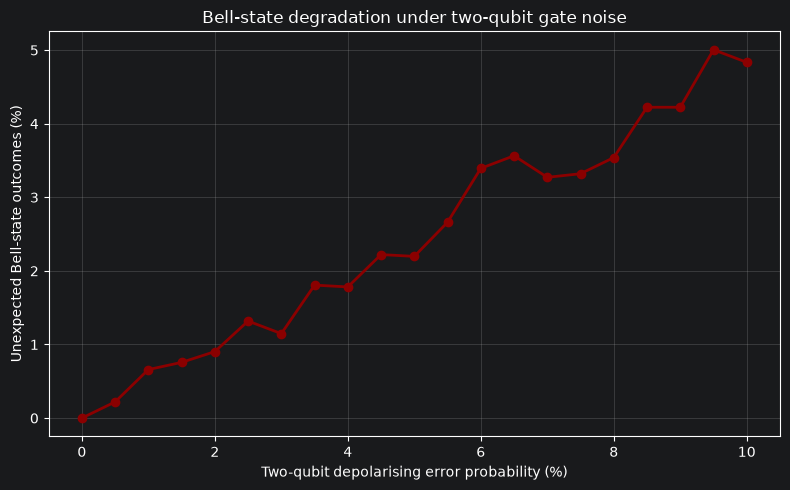

Saved figure to: C:\Users\Karthi\Qauntum\figures\bell_state_error_rate_sweep.png


In [76]:
# Initialise a Matplotlib figure and single subplot axis
figure, axis = plt.subplots(
    figsize=(8, 5)
)

# Plot unexpected outcome rate (%) against two-qubit depolarising error probability (%)
axis.plot(
    100.0
    * noise_sweep_df[
        "two_qubit_error_probability"
    ],
    100.0
    * noise_sweep_df[
        "unexpected_outcome_rate"
    ],
    marker="o",
    linewidth=2,
    color="darkred",
)

# Set axis labels, title, and grid
axis.set_xlabel(
    "Two-qubit depolarising error probability (%)"
)

axis.set_ylabel(
    "Unexpected Bell-state outcomes (%)"
)

axis.set_title(
    "Bell-state degradation under two-qubit gate noise"
)

axis.grid(
    True,
    alpha=0.3,
)

figure.tight_layout()

# Save the figure as a high-resolution PNG and render it in the notebook
error_sweep_figure_path = (
    FIGURE_DIR
    / "bell_state_error_rate_sweep.png"
)

figure.savefig(
    error_sweep_figure_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print(
    f"Saved figure to: "
    f"{error_sweep_figure_path}"
)

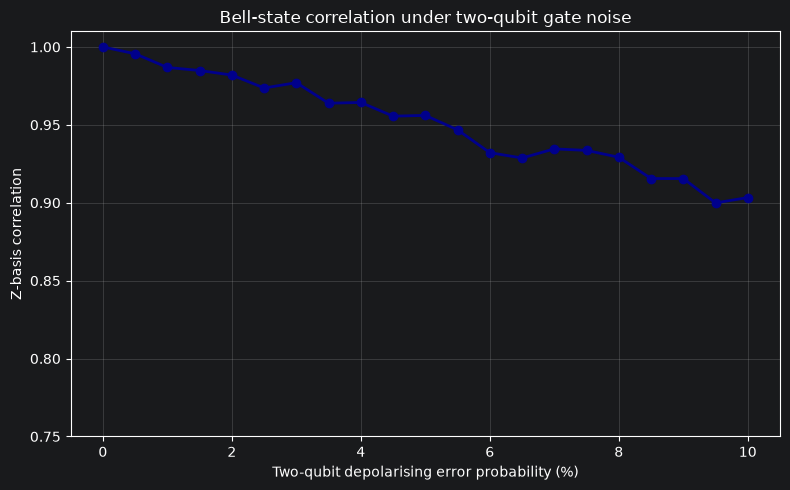

Saved figure to: C:\Users\Karthi\Qauntum\figures\bell_state_correlation_sweep.png


In [77]:
# Initialise a Matplotlib figure and single subplot axis
figure, axis = plt.subplots(
    figsize=(8, 5)
)

# Plot Z-basis correlation against two-qubit depolarising error probability (%)
axis.plot(
    100.0
    * noise_sweep_df[
        "two_qubit_error_probability"
    ],
    noise_sweep_df[
        "zz_correlation"
    ],
    marker="o",
    linewidth=2,
    color="darkblue",
)

# Set axis labels, title, y-axis bounds, and grid
axis.set_xlabel(
    "Two-qubit depolarising error probability (%)"
)

axis.set_ylabel(
    "Z-basis correlation"
)

axis.set_title(
    "Bell-state correlation under two-qubit gate noise"
)

axis.set_ylim(
    0.75,
    1.01,
)

axis.grid(
    True,
    alpha=0.3,
)

figure.tight_layout()

# Save the figure as a high-resolution PNG and render it in the notebook
correlation_sweep_figure_path = (
    FIGURE_DIR
    / "bell_state_correlation_sweep.png"
)

figure.savefig(
    correlation_sweep_figure_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print(
    f"Saved figure to: "
    f"{correlation_sweep_figure_path}"
)

In [78]:
# Compute exact Z-basis correlation from error rate: <ZZ> = P(same) - P(diff) = 1 - 2*P(diff)
noise_sweep_df[
    "predicted_zz_correlation"
] = (
    1.0
    - 2.0
    * noise_sweep_df[
        "unexpected_outcome_rate"
    ]
)

# Calculate the numerical discrepancy between measured and algebraic correlation values
noise_sweep_df[
    "correlation_difference"
] = (
    noise_sweep_df[
        "zz_correlation"
    ]
    - noise_sweep_df[
        "predicted_zz_correlation"
    ]
)

# Verify exact agreement across all sweep points within floating-point precision
maximum_correlation_difference = (
    noise_sweep_df[
        "correlation_difference"
    ]
    .abs()
    .max()
)

print(
    "Maximum difference between measured and "
    "predicted correlation: "
    f"{maximum_correlation_difference:.12f}"
)

assert maximum_correlation_difference < 1e-12

Maximum difference between measured and predicted correlation: 0.000000000000


In [79]:
# Export the noise-sweep DataFrame to CSV without the default row index
noise_sweep_csv_path = (
    RESULTS_DIR
    / "bell_state_noise_sweep.csv"
)

noise_sweep_df.to_csv(
    noise_sweep_csv_path,
    index=False,
)

# Confirm the CSV save location
print(
    f"Saved results to: "
    f"{noise_sweep_csv_path}"
)

Saved results to: C:\Users\Karthi\Qauntum\results\bell_state_noise_sweep.csv


### Noise-sweep interpretation

Increasing the two-qubit depolarising error probability increased the frequency of the unexpected outcomes `01` and `10`. These outcomes represent a loss of the ideal Z-basis correlation between the two measured qubits.

Correspondingly, the measured Z-basis correlation decreased as the two-qubit gate error increased. The correlation and unexpected-outcome rate are related by $\langle Z \otimes Z \rangle = 1 - 2P(\text{unexpected})$, because outcomes `00` and `11` contribute `+1` to the correlation while outcomes `01` and `10` contribute `-1`.

The results contain finite-shot fluctuations because each error probability was evaluated using 4,096 circuit executions. The trend is nevertheless clear across the full sweep.

The single-qubit error probability was held at `1%`, so the result at zero two-qubit error is not completely noise-free. A fully ideal baseline would require both error probabilities to be set to zero.

This experiment models only one Bell-state preparation and uses a simplified depolarising channel. It does not represent repeated syndrome extraction, logical encoding, or fault-tolerant operation. However, it establishes the simulation, analysis, and reproducibility methods needed for later quantum error-correction experiments.
